---
title: "L4-08 · Causal discovery and its limits"
short_title: "Causal discovery and its limits"
subtitle: "Under the Markov and faithfulness assumptions, perfect independence tests reveal a graph's skeleton and its v-structures and nothing more; every further arrow needs extra assumptions, interventions, or restrictions on the mechanisms."
description: "Explain what conditional independences can and cannot reveal about a causal graph: characterize Markov equivalence, run the PC algorithm, and recognize how faithfulness violations, test errors and modeling assumptions limit discovery."
tags: [level-4, coursebook]
---

(lesson-l4-08)=

:::{div}
:class: qcai-meta
![Level 4 icon](../../_static/icons/qicon-level-4.svg) **Level 4 · Undergraduate** · about 110 minutes  
**Big idea.** Under the Markov and faithfulness assumptions, perfect independence tests reveal a graph's skeleton and its v-structures and nothing more; every further arrow needs extra assumptions, interventions, or restrictions on the mechanisms.  
**Before this lesson.** [L4-02](#lesson-l4-02), [L4-07](#lesson-l4-07), [L3-09](#lesson-l3-09)  
**Lab.** [Confounding and intervention](../../labs/03-causal-inference.ipynb)
:::

## What you will be able to do

- Decide whether two DAGs are Markov equivalent with the Verma-Pearl criterion, and list the members of a small equivalence class.
- Run the PC algorithm by hand (skeleton search, collider orientation, Meek's rules) and state the assumptions under which it returns the correct pattern.
- Construct a faithfulness violation by path cancellation and predict the wrong graph that PC then reports.
- Explain what a continuous method such as NOTEARS adds (a smooth acyclicity constraint) and which assumptions it leaves in place.

## Why this matters

Three variables, thousands of records, and one clean finding: $X$ and $Z$ are dependent, but independent once $Y$ is known. A chain $X \to Y \to Z$ explains this. So does $Z \to Y \to X$, and so does the fork $X \leftarrow Y \to Z$. The three stories disagree about what happens if you intervene on $X$: in the first $Z$ moves, in the other two it does not. No test of independence, on any amount of data, can separate them, because all three graphs imply exactly the same independences.

Causal discovery algorithms, available in libraries such as causal-learn [@causallearn], promise graphs from data. This lesson measures what they can actually deliver. With perfect tests and the right assumptions they return an equivalence class, often with many arrows left undecided. When two causal paths happen to cancel, or a test misses a weak dependence, they return a wrong graph with no warning. And an optimizer that outputs a single DAG has solved its objective, which is not the same as finding the mechanism. As in [L4-07](#lesson-l4-07), the limits are limits of identification, not of sample size.

:::{dropdown} Key terms

**Markov condition**
: Every d-separation in the graph holds as a conditional independence in the distribution.

**Faithfulness**
: The converse: every conditional independence in the distribution comes from a d-separation in the graph, not from a numerical coincidence.

**Skeleton**
: The undirected graph obtained by forgetting the direction of every edge.

**V-structure**
: An unshielded collider $a \to m \leftarrow c$ in which $a$ and $c$ are not adjacent.

**Markov equivalence class**
: The set of DAGs that imply exactly the same conditional independences.

**Pattern (CPDAG)**
: A partially directed graph that represents an equivalence class: arrows shared by every member are directed, the rest are undirected.

**Causal sufficiency**
: No unmeasured variable is a common cause of two measured variables.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l4_08 as _lessonfigs

## What independences can reveal

In [L4-02](#lesson-l4-02) you read independences off a graph: d-separation implies conditional independence under the Markov condition. Discovery runs the other way, from independences to a graph, and needs the converse too.

:::{prf:definition} Markov condition and faithfulness
:label: def-l4-08-faithful
Let $P$ be a distribution over the variables of a DAG $G$. $P$ is **Markov** to $G$ if every d-separation $(A \perp\!\!\!\perp B \mid S)_G$ implies $A \perp\!\!\!\perp B \mid S$ in $P$. $P$ is **faithful** to $G$ if the converse holds: every conditional independence $A \perp\!\!\!\perp B \mid S$ in $P$ implies the d-separation $(A \perp\!\!\!\perp B \mid S)_G$. A distribution that is both Markov and faithful to $G$ satisfies equation [](#eq-l4-08-faith) below.
:::

$$
(A \perp\!\!\!\perp B \mid S)_G \iff A \perp\!\!\!\perp B \mid S \text{ in } P \quad \text{for all disjoint } A, B, S
$$ (eq-l4-08-faith)

Under [](#eq-l4-08-faith) the independence model of $P$ is exactly the d-separation model of $G$. The question becomes: which graphs share a d-separation model?

:::{figure} ../../_static/animations/l4_08_markov_equivalence.mp4
:alt: Three nodes X, Y, Z in a row. The arrows flip from chain to reverse chain to fork while the listed independences stay the same; then the collider X to Y from Z swaps them. Mini graphs group the first three into one class and the collider into its own.
:width: 100%

Flipping arrows on the skeleton $X - Y - Z$: three orientations imply the same independences; only the collider changes them.
:::

:::{dropdown} What the animation shows
The skeleton $X - Y - Z$ is oriented as the chain $X \to Y \to Z$, and the implied statements appear: $X \not\perp\!\!\!\perp Z$ and $X \perp\!\!\!\perp Z \mid Y$. The arrows then flip to the reverse chain $X \leftarrow Y \leftarrow Z$ and to the fork $X \leftarrow Y \to Z$; each time the statements flash and a label says they are the same. When the arrows become the collider $X \to Y \leftarrow Z$, the statements change to $X \perp\!\!\!\perp Z$ and $X \not\perp\!\!\!\perp Z \mid Y$. Small copies of the three equivalent graphs appear in one box with the shared pattern $X - Y - Z$, the collider sits in a box of its own, and the closing line states the theorem: Markov equivalent if and only if same skeleton and same v-structures (Verma and Pearl).
:::

:::{prf:theorem} Markov equivalence (Verma and Pearl)
:label: thm-l4-08-vp
Two DAGs on the same variables imply the same d-separations, that is, they are Markov equivalent, if and only if they have the same skeleton and same v-structures [@pearlcausality; @spirtes; @peters].
:::

:::{prf:proof}
*Only if.* (i) Adjacent nodes are d-separated by no set, since the edge is a path with no interior node. Nonadjacent nodes $a, b$ are d-separated by some set: if $b$ is not an ancestor of $a$ (relabel otherwise), then $a$ is a non-descendant of $b$ and the parents of $b$ d-separate $b$ from all its non-descendants. So adjacency means "no separating set", a property of the independence model, and equivalent DAGs have the same skeleton. (ii) Take an unshielded triple $a - m - c$. If $m$ is a noncollider (chain or fork), the path $a - m - c$ is open unless $m$ is conditioned on, so $m$ belongs to every separating set of $a$ and $c$. If $m$ is a collider $a \to m \leftarrow c$, label so that $c$ is not an ancestor of $a$; then the parents of $c$ separate $a$ and $c$, and $m$, a child of $c$, is not among them. So "$m$ lies in every separating set of $a, c$" holds exactly for noncolliders, and equivalent DAGs have the same v-structures.

*If* (sketch). One shows that whenever a path d-connects two nodes given $S$ in one DAG, some path d-connects them given $S$ in the other; the argument walks along the path and uses the shared skeleton and shared unshielded colliders to replace each segment. The theorem is due to Verma and Pearl (1990) and is stated, with references to the full proof, in Pearl's *Causality* and in Spirtes, Glymour and Scheines [@pearlcausality; @spirtes].
:::


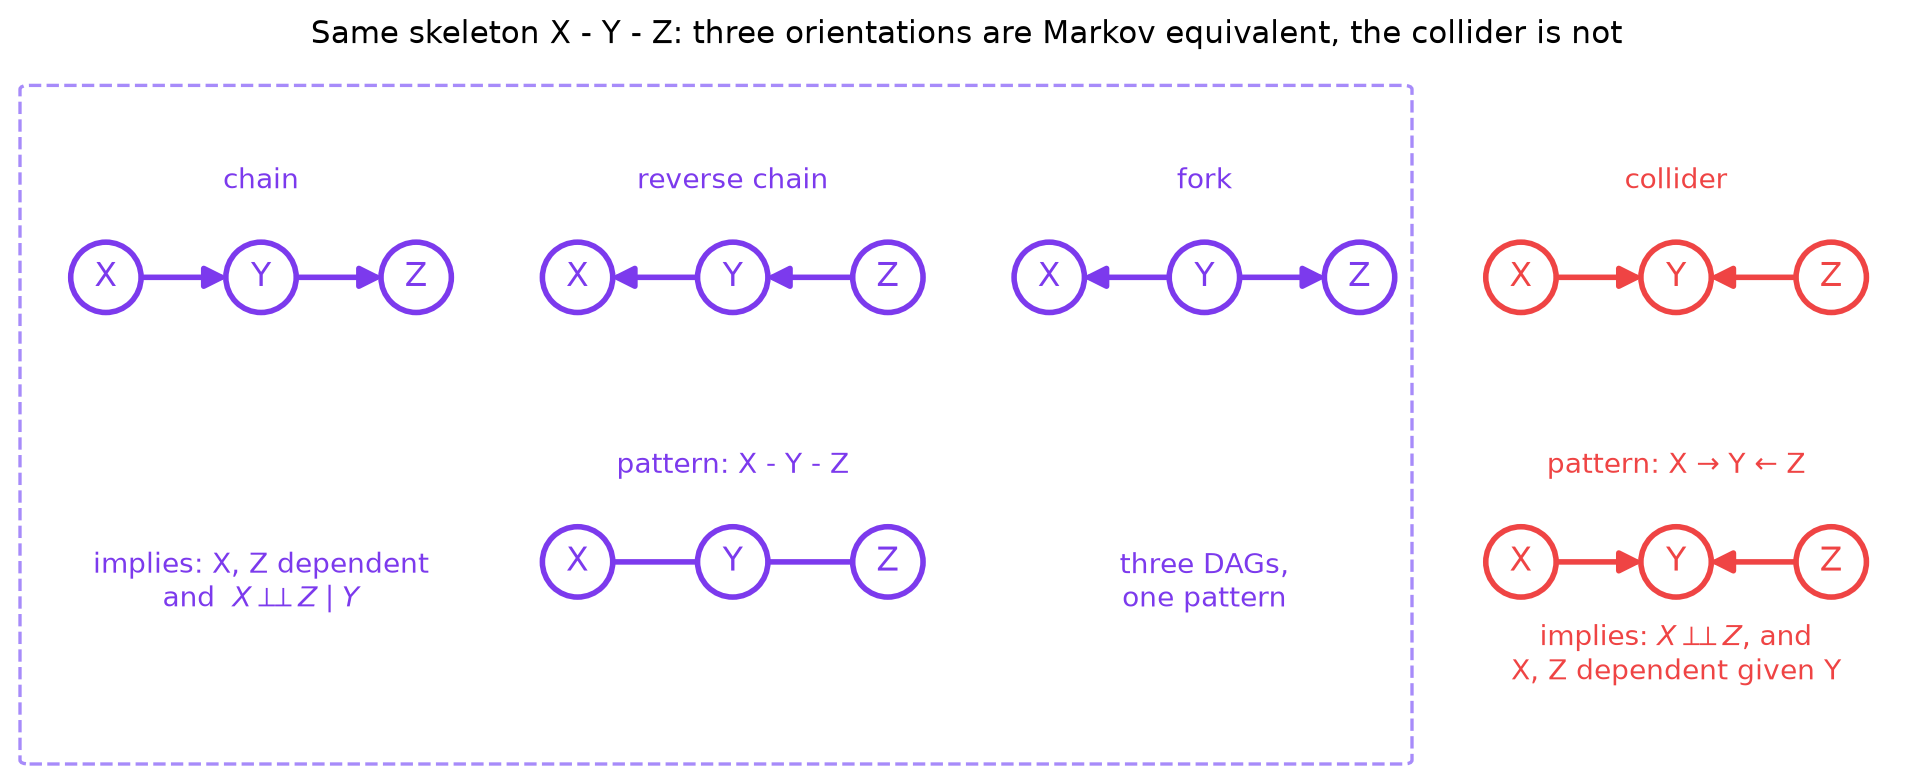

In [2]:
_show_mpl(_lessonfigs.equivalence_classes())

*The four DAGs on the skeleton $X - Y - Z$. Chain, reverse chain and fork (violet, dashed box) form one class with pattern $X - Y - Z$; the collider (red) is a class of one with pattern $X \to Y \leftarrow Z$. Every claim in the figure is checked by d-separation in the figure code.*

Check the Verma-Pearl theorem by brute force: enumerate every DAG on three and on four labeled nodes, group them once by skeleton and v-structures and once by their full lists of d-separations, and confirm that the two groupings coincide.


In [3]:
import itertools
from collections import defaultdict
import networkx as nx

def all_dags(nodes):
    """Every DAG on the labeled nodes: each pair gets no edge, a -> b, or b -> a."""
    pairs = list(itertools.combinations(nodes, 2))
    for choice in itertools.product((0, 1, 2), repeat=len(pairs)):
        g = nx.DiGraph()
        g.add_nodes_from(nodes)
        g.add_edges_from((a, b) if c == 1 else (b, a) for (a, b), c in zip(pairs, choice) if c)
        if nx.is_directed_acyclic_graph(g):
            yield g

def invariants(g):
    """Skeleton and v-structures (unshielded colliders a -> b <- c)."""
    skel = frozenset(frozenset(e) for e in g.edges)
    v = frozenset((frozenset((a, c)), b) for b in g for a, c in itertools.combinations(sorted(g.predecessors(b)), 2)
                  if not (g.has_edge(a, c) or g.has_edge(c, a)))
    return skel, v

def independences(g):
    """All d-separation statements a _||_ b | S with S drawn from the other nodes."""
    out = set()
    for a, b in itertools.combinations(sorted(g), 2):
        rest = [n for n in g if n not in (a, b)]
        for k in range(len(rest) + 1):
            for S in itertools.combinations(rest, k):
                if nx.is_d_separator(g, {a}, {b}, set(S)):
                    out.add((a, b, S))
    return frozenset(out)

for nodes in ("XYZ", "WXYZ"):
    by_vp, by_ci = defaultdict(list), defaultdict(list)
    dags = list(all_dags(list(nodes)))
    for i, g in enumerate(dags):
        by_vp[invariants(g)].append(i)
        by_ci[independences(g)].append(i)
    same = sorted(map(sorted, by_vp.values())) == sorted(map(sorted, by_ci.values()))
    sizes = sorted(len(c) for c in by_ci.values())
    print(f"{len(nodes)} nodes: {len(dags)} DAGs, {len(by_ci)} classes; Verma-Pearl grouping = d-separation grouping: {same}")
    if len(nodes) == 3:
        print("   class sizes:", sizes)

3 nodes: 25 DAGs, 11 classes; Verma-Pearl grouping = d-separation grouping: True
   class sizes: [1, 1, 1, 1, 2, 2, 2, 3, 3, 3, 6]


4 nodes: 543 DAGs, 185 classes; Verma-Pearl grouping = d-separation grouping: True


## The PC algorithm

:::{prf:algorithm} PC (Spirtes and Glymour)
:label: alg-l4-08-pc
Input: variables $V$ and a conditional-independence test. Output: a pattern.

1. **Skeleton.** Start from the complete undirected graph. For $\ell = 0, 1, 2, \dots$: for each adjacent pair $a, b$ and each set $S$ of $\ell$ current neighbors of $a$ other than $b$, if the test accepts $a \perp\!\!\!\perp b \mid S$, delete the edge and record $\mathrm{sep}(a, b) = S$. Stop when no node has more than $\ell$ other neighbors.
2. **Colliders.** For each unshielded triple $a - m - c$ with $m \notin \mathrm{sep}(a, c)$, orient $a \to m \leftarrow c$.
3. **Propagation (Meek's rules).** Repeat until nothing changes. Rule 1: if $r \to p - q$ and $r, q$ are not adjacent, orient $p \to q$ (otherwise a new collider would appear). Rule 2: if $p \to r \to q$ and $p - q$, orient $p \to q$ (otherwise a cycle). Rule 3: if $p - r \to q$, $p - s \to q$, $r, s$ nonadjacent and $p - q$, orient $p \to q$ [@meek1995; @spirtes].
:::

:::{figure} ../../_static/animations/l4_08_pc_run.mp4
:alt: Five nodes V, W, X, Y, Z start fully connected. Edges turn red and vanish as separation statements are listed; then W to Y and X to Y become red arrows, Y to Z becomes a blue arrow, and V to W and V to X stay undirected.
:width: 100%

PC on data from $V \to W$, $V \to X$, $W \to Y$, $X \to Y$, $Y \to Z$, driven by a d-separation oracle: five deletions, one collider, one Meek step.
:::

:::{dropdown} What the animation shows
The five nodes start with all ten edges. No pair is independent without conditioning, so nothing is removed at size 0. Then five edges are deleted one by one as their tests are written: $V \perp\!\!\!\perp Z \mid Y$, $W \perp\!\!\!\perp X \mid V$, $W \perp\!\!\!\perp Z \mid Y$, $X \perp\!\!\!\perp Z \mid Y$ and, with a two-element set, $V \perp\!\!\!\perp Y \mid W, X$. The skeleton $V - W$, $V - X$, $W - Y$, $X - Y$, $Y - Z$ remains. In the triple $W - Y - X$, $Y$ is not in $\mathrm{sep}(W, X) = \{V\}$, so the edges become red arrows $W \to Y \leftarrow X$. Meek rule 1 applies to $W \to Y - Z$ with $W$ and $Z$ not adjacent, giving the blue arrow $Y \to Z$. The edges $V - W$ and $V - X$ flash: they stay undirected, and the output is a pattern.
:::

The run in the animation is the actual output of the algorithm on the true graph's d-separations. The key deletions are $W \perp\!\!\!\perp X \mid V$ (the fork at $V$ is blocked by conditioning on $V$) and $V \perp\!\!\!\perp Y \mid W, X$, which needs both mediating paths blocked at once. The undirected edges $V - W$ and $V - X$ are genuine ambiguity: orienting them as $V \to W, V \to X$ or $W \to V \to X$ or $X \to V \to W$ gives three DAGs with the same skeleton and the same single v-structure, while $W \to V \leftarrow X$ would add a v-structure and is excluded.

```{mermaid}
graph TD
  V --- W
  V --- X
  W --> Y
  X --> Y
  Y --> Z
```

*The pattern PC returns. Lines without arrowheads are undecided by independences; the class has three member DAGs.*

:::{prf:theorem} Correctness of PC
:label: thm-l4-08-pc
Assume causal sufficiency, that $P$ is Markov and faithful to a DAG $G$, and that every test answer is correct. Then PC returns the skeleton of $G$, orients exactly the v-structures of $G$ in step 2, and every arrow added in step 3 is shared by all DAGs in the Markov equivalence class of $G$ [@spirtes].
:::

:::{prf:remark} What the theorem does not promise
Every assumption carries weight. Without causal sufficiency, a hidden common cause can create dependences that PC turns into spurious edges or arrows; algorithms such as FCI address this with a richer output. The number of tests grows exponentially with the largest neighborhood size in the worst case. And the theorem is about a perfect test oracle; with data, each test can err, and an early error changes later separating sets and orientations (exercise 6). Meek [@meek1995] also showed that rules 1 to 3 orient every edge that the class determines, so each edge left undirected really does point both ways in some member of the class.
:::

## Testing independence from data

For jointly Gaussian variables, $a \perp\!\!\!\perp b \mid S$ holds exactly when the partial correlation $\rho_{ab \cdot S}$ is zero. The Fisher $z$-test uses the sample partial correlation $r$ from $n$ records:

$$
z = \tfrac12 \ln\frac{1 + r}{1 - r}\,\sqrt{n - |S| - 3}, \qquad z \approx \mathcal{N}(0, 1) \text{ when } \rho_{ab \cdot S} = 0
$$ (eq-l4-08-fisher)

:::{caution} Accepting independence is a decision, not a finding
PC deletes an edge when a test fails to reject independence. Failing to reject is not evidence of independence; with $n = 200$ and level $0.05$, a population correlation below about $0.14$ in size is usually missed, since $1.96/\sqrt{197} \approx 0.14$. For non-Gaussian or nonlinear data, zero partial correlation does not imply conditional independence, and kernel or other nonparametric tests are needed [@causallearn].
:::

A compact PC with the Fisher $z$-test, run on 5000 simulated records from the five-node graph. It prints each deletion with its separating set, the pattern, and the three DAGs the pattern stands for.


In [4]:
import numpy as np
from scipy import stats

def fisher_z(data, a, b, S, alpha=0.05):
    """Test zero partial correlation of columns a, b given S; True means 'cannot reject independence'."""
    idx = [a, b] + list(S)
    P = np.linalg.inv(np.corrcoef(data[:, idx], rowvar=False))
    r = -P[0, 1] / np.sqrt(P[0, 0] * P[1, 1])
    z = 0.5 * np.log((1 + r) / (1 - r)) * np.sqrt(len(data) - len(S) - 3)
    return 2 * stats.norm.sf(abs(z)) > alpha

def pc(names, indep):
    """Skeleton search, collider orientation and Meek rule 1 (enough for these examples)."""
    adj = {v: set(names) - {v} for v in names}
    sep, level = {}, 0
    while any(len(adj[v]) - 1 >= level for v in names):
        for a in names:
            for b in sorted(adj[a]):
                for S in itertools.combinations(sorted(adj[a] - {b}), level):
                    if b in adj[a] and indep(a, b, S):
                        adj[a].discard(b); adj[b].discard(a)
                        sep[frozenset((a, b))] = set(S)
                        print(f"   remove {a} - {b}   given {{{', '.join(S)}}}")
        level += 1
    arrows = set()
    for m in names:
        for a, c in itertools.combinations(sorted(adj[m]), 2):
            if c not in adj[a] and m not in sep[frozenset((a, c))]:
                arrows |= {(a, m), (c, m)}
    changed = True
    while changed:                          # Meek rule 1: r -> p - q, r and q not adjacent  =>  p -> q
        changed = False
        for (r, p) in list(arrows):
            for q in adj[p]:
                if q != r and q not in adj[r] and (p, q) not in arrows and (q, p) not in arrows:
                    arrows.add((p, q)); changed = True
    lines = {tuple(sorted((a, b))) for a in names for b in adj[a]
             if (a, b) not in arrows and (b, a) not in arrows}
    return sorted(arrows), sorted(lines)

# linear Gaussian data from V -> W, V -> X, W -> Y, X -> Y, Y -> Z
rng = np.random.default_rng(1)
n = 5000
V = rng.normal(size=n)
W = 0.9 * V + rng.normal(size=n)
X = 0.8 * V + rng.normal(size=n)
Y = 0.7 * W + 0.9 * X + rng.normal(size=n)
Z = 0.8 * Y + rng.normal(size=n)
data = np.column_stack([V, W, X, Y, Z])
names = list("VWXYZ")
col = {v: i for i, v in enumerate(names)}
arrows, lines = pc(names, lambda a, b, S: fisher_z(data, col[a], col[b], [col[s] for s in S]))
print("directed:  ", arrows)
print("undirected:", lines)

# the DAGs this pattern stands for: orient the undirected edges without new v-structures or cycles
truth = nx.DiGraph([("V", "W"), ("V", "X"), ("W", "Y"), ("X", "Y"), ("Y", "Z")])
members = []
for flips in itertools.product((0, 1), repeat=len(lines)):
    g = nx.DiGraph(arrows + [(a, b) if f == 0 else (b, a) for (a, b), f in zip(lines, flips)])
    if nx.is_directed_acyclic_graph(g) and invariants(g) == invariants(truth):
        members.append(sorted((a, b) for a, b in g.edges if (a, b) not in arrows))
print("members of the class (orientations of the undirected edges):", members)

   remove V - Z   given {Y}
   remove W - X   given {V}
   remove W - Z   given {Y}
   remove X - Z   given {Y}
   remove V - Y   given {W, X}
directed:   [('W', 'Y'), ('X', 'Y'), ('Y', 'Z')]
undirected: [('V', 'W'), ('V', 'X')]
members of the class (orientations of the undirected edges): [[('V', 'W'), ('V', 'X')], [('V', 'W'), ('X', 'V')], [('V', 'X'), ('W', 'V')]]


## Faithfulness and cancellation

Faithfulness can fail. Take $X \to Y \to Z$ together with $X \to Z$, linear with weights $a$ on $X \to Y$, $b$ on $Y \to Z$, $c$ on $X \to Z$, and independent standard normal noises: $X = N_X$, $Y = aX + N_Y$, $Z = cX + bY + N_Z$. Substituting, $Z = (c + ab)X + bN_Y + N_Z$, so $\mathrm{Cov}(X, Z) = c + ab$: the direct path contributes $c$ and the path through $Y$ contributes $ab$.

$$
\mathrm{corr}(X, Z) = \frac{c + ab}{\sqrt{(c + ab)^2 + b^2 + 1}}, \qquad \mathrm{corr}(X, Z \mid Y)\big|_{c = -ab} = \frac{-ab}{\sqrt{a^2b^2 + a^2 + 1}}
$$ (eq-l4-08-cancel)

:::{figure} ../../_static/animations/l4_08_faithfulness.mp4
:alt: A triangle graph X to Y to Z with an orange direct arrow X to Z of weight c. As c sweeps, a violet curve of corr(X, Z) and a cyan curve of the partial correlation are traced; at c = -0.8 the violet curve crosses zero, and the graph is replaced by the wrong output X to Y from Z.
:width: 100%

With $a = 0.8$ and $b = 1$, the direct effect $c = -0.8$ cancels the indirect one exactly. PC then reports a collider that is not there.
:::

:::{dropdown} What the animation shows
The graph has $X \to Y$ with $a = 0.8$, $Y \to Z$ with $b = 1$ and an orange direct arrow $X \to Z$ with weight $c$; below it is $\mathrm{Cov}(X, Z) = c + ab$ for unit-variance Gaussian noises. As $c$ sweeps from $0.4$ down to $-1.6$, two curves are traced: $\mathrm{corr}(X, Z)$ in violet and $\mathrm{corr}(X, Z \mid Y)$ in cyan. The tracker returns to $c = -ab = -0.8$, where a red dashed line marks the zero of the violet curve: $X$ and $Z$ are uncorrelated although $X \to Z$ exists, while the partial correlation is about $-0.53$. The graph is then replaced by PC's output $X \to Y \leftarrow Z$ in red, with the reasons: the edge $X - Z$ is removed because $X$ and $Z$ test independent, $Y$ is not in their separating set so a collider is oriented, and the result misses an edge and reverses $Y \to Z$.
:::

At $c = -ab = -0.8$, $X$ and $Z$ are exactly independent although $X$ causes $Z$, and given $Y$ they are dependent with partial correlation $-0.8/\sqrt{2.28} \approx -0.53$, by [](#eq-l4-08-cancel). That is exactly the independence pattern of a collider, so PC deletes $X - Z$ with $\mathrm{sep}(X, Z) = \emptyset$ and orients $X \to Y \leftarrow Z$. The output is not merely incomplete; it is wrong, and confidently so: it reverses $Y \to Z$ and it would tell you that intervening on $Z$ changes $Y$.

:::{prf:proposition} Exact violations have measure zero
:label: prop-l4-08-measure
For a linear Gaussian model on a fixed DAG, the set of edge weights for which $P$ is not faithful has Lebesgue measure zero [@spirtes]. The reason: each unfaithful independence forces a nonzero polynomial in the weights, such as $c + ab$, to vanish, and the zero set of a nonzero polynomial has measure zero.
:::


In [5]:
_show(_lessonfigs.faithfulness_explorer())

**Explore.** Slide the direct weight $c$. The gray band marks correlations too small for a 5% test with $n = 200$ to detect reliably; whenever a curve enters it, PC's output on the right changes.

:::{dropdown} What the figure shows
The first panel plots $\mathrm{corr}(X, Z)$ (violet) and $\mathrm{corr}(X, Z \mid Y)$ (cyan, dashed) against $c$ from $-1.6$ to $0.3$, with a gray band between $-0.14$ and $0.14$ and markers at the chosen $c$. The second panel draws the graph PC outputs when every population correlation inside the band is treated as independence. For most $c$ the output is the complete undirected triangle, which is correct but uninformative. For $c$ between about $-1.0$ and $-0.6$ the marginal correlation is inside the band and the output is the wrong collider $X \to Y \leftarrow Z$. For small $|c|$ the partial correlation is inside the band and the output is the undirected chain $X - Y - Z$, which misses the weak direct edge.
:::

The proposition is reassuring only about exact cancellation. With finite samples what matters is near cancellation, and the slider shows a whole interval of $c$, here roughly $-1.0$ to $-0.6$, in which a test at $n = 200$ behaves as if faithfulness failed. Such intervals shrink as $n$ grows but do not vanish for any fixed $n$, and with more variables there are more paths that can nearly cancel.

Simulate the cancelling model and run the same PC on it. At exact cancellation with $n = 5000$, and at the near-cancelling $c = -0.75$ with $n = 200$, the output is the collider; at $c = 0.4$ PC correctly keeps all three edges, and cannot orient any of them.


In [6]:
def sample(c, n, seed, a=0.8, b=1.0):
    r = np.random.default_rng(seed)
    X = r.normal(size=n)
    Y = a * X + r.normal(size=n)
    Z = c * X + b * Y + r.normal(size=n)
    return np.column_stack([X, Y, Z])

def partial_r(data, a, b, S):
    idx = [a, b] + list(S)
    P = np.linalg.inv(np.corrcoef(data[:, idx], rowvar=False))
    return -P[0, 1] / np.sqrt(P[0, 0] * P[1, 1])

for c, n in ((-0.8, 5000), (-0.75, 200), (0.4, 200)):
    d = sample(c, n, seed=3)
    print(f"c = {c:5}, n = {n}: corr(X,Z) = {partial_r(d, 0, 2, []):+.3f}, corr(X,Z | Y) = {partial_r(d, 0, 2, [1]):+.3f}")
    arrows, lines = pc(list("XYZ"), lambda a, b, S: fisher_z(d, "XYZ".index(a), "XYZ".index(b), ["XYZ".index(s) for s in S]))
    print("   PC output -> directed", arrows, " undirected", lines)

c =  -0.8, n = 5000: corr(X,Z) = +0.003, corr(X,Z | Y) = -0.545
   remove X - Z   given {}
   PC output -> directed [('X', 'Y'), ('Z', 'Y')]  undirected []
c = -0.75, n = 200: corr(X,Z) = -0.014, corr(X,Z | Y) = -0.562
   remove X - Z   given {}
   PC output -> directed [('X', 'Y'), ('Z', 'Y')]  undirected []
c =   0.4, n = 200: corr(X,Z) = +0.651, corr(X,Z | Y) = +0.249
   PC output -> directed []  undirected [('X', 'Y'), ('X', 'Z'), ('Y', 'Z')]


## Beyond independence tests

Independences alone stop at the equivalence class. Other methods add assumptions that break the symmetry [@peters].

- **Restrictions on mechanisms.** If noises are non-Gaussian in a linear model, or effects are nonlinear with additive noise, the direction between two variables can become identifiable, because the reverse model would not have independent noise. These are assumptions about nature, not consequences of data.
- **Invariance across environments.** If the mechanism for $Y$ stays the same across settings while other parts change, the sets of predictors with invariant residuals point to the causes of $Y$ [@invariant].
- **Interventions.** Data from an experiment that sets one variable cut its incoming arrows, which can orient edges an observational class leaves open [@bareinboim].
- **Scores and optimization.** Score-based methods search over graphs for the best penalized fit; NOTEARS turns that search into continuous optimization [@notears].

:::{prf:proposition} The NOTEARS acyclicity function
:label: prop-l4-08-notears
For a real $d \times d$ matrix $W$ with weighted graph $G(W)$ (edge $i \to j$ when $W_{ij} \ne 0$), let $W \circ W$ be the elementwise square and $h(W) = \operatorname{tr}(e^{W \circ W}) - d$. Then $h(W) \ge 0$, and $h(W) = 0$ exactly when $G(W)$ has no directed cycle, as restated in [](#eq-l4-08-notears).
:::

$$
h(W) = \operatorname{tr}\big(e^{W \circ W}\big) - d \;\ge\; 0, \qquad h(W) = 0 \iff G(W) \text{ has no directed cycle}
$$ (eq-l4-08-notears)

:::{prf:proof}
Put $A = W \circ W$, whose entries are nonnegative and positive exactly on the edges of $G(W)$. The diagonal entry $(A^k)_{ii}$ is a sum, over closed walks of length $k$ from $i$ back to $i$, of products of positive weights, so $\operatorname{tr}(A^k) \ge 0$ with equality exactly when there is no closed walk of length $k$. Since $e^{A} = \sum_{k \ge 0} A^k/k!$ and $\operatorname{tr}(A^0) = d$, we get $h(W) = \sum_{k \ge 1} \operatorname{tr}(A^k)/k! \ge 0$, with equality exactly when there are no closed walks of any length, that is, no directed cycles [@notears].
:::

Check the acyclicity function with `scipy.linalg.expm`, then see a limit of least-squares scores: in the true model $X \to Y$ with $Y = X + N$, a score that adds the residual variances of a cause and its effect prefers the right direction, until $X$ is merely recorded in different units.


In [7]:
from scipy.linalg import expm

def h(W):
    """NOTEARS acyclicity function: trace(exp(W * W)) - d, with * the elementwise product."""
    return np.trace(expm(W * W)) - W.shape[0]

dag = np.array([[0, 0.9, -0.8], [0, 0, 0.7], [0, 0, 0]])     # X -> Y, X -> Z, Y -> Z
cyc = dag.copy(); cyc[2, 0] = 0.5                            # add Z -> X: a directed 3-cycle
print(f"h(DAG) = {h(dag):.2e}    h(cyclic) = {h(cyc):.4f}")
A = cyc * cyc                                                  # weighted closed walks of length 3
print(f"first cycle term tr(A^3)/3! = {np.trace(A @ A @ A) / 6:.4f}")

# a least-squares score with equal noise variances depends on the units of measurement
def ls_score(var_cause, var_effect, cov):
    """Residual variance of the cause plus that of the effect regressed on the cause."""
    return var_cause + var_effect - cov ** 2 / var_cause

for scale in (1, 10):                  # true model X -> Y, Y = X + N; X then recorded as scale * X
    vx, vy, cxy = scale ** 2, 2.0, float(scale)
    fwd, bwd = ls_score(vx, vy, cxy), ls_score(vy, vx, cxy)
    print(f"X rescaled by {scale:>2}: score X->Y = {fwd:6.1f}, Y->X = {bwd:6.1f}, prefers {'X->Y' if fwd < bwd else 'Y->X'}")

h(DAG) = 0.00e+00    h(cyclic) = 0.2125
first cycle term tr(A^3)/3! = 0.0496
X rescaled by  1: score X->Y =    2.0, Y->X =    2.5, prefers X->Y
X rescaled by 10: score X->Y =  101.0, Y->X =   52.0, prefers Y->X


:::{warning} What a returned graph establishes
NOTEARS minimizes a least-squares loss plus a sparsity penalty subject to $h(W) = 0$, a nonconvex problem whose solvers return local solutions. The code shows that such losses can depend on the units of measurement; on common simulated benchmarks, where variances tend to grow along the causal order, continuous methods partly exploit that pattern and lose much of their accuracy once the data are standardized [@reisach2021]. A solver that returns one graph has found a solution under its model and objective. That does not show there is no hidden common cause, that the functional form is right, or that the graph is the unique explanation of the data.
:::

## Worked example

:::{admonition} PC by hand on four variables
:class: tip

The true graph is $X \to Y \to Z \leftarrow W$, all variables are measured, and the tests are perfect (they report d-separation). Run PC and give the pattern and the members of its class.

1. Size 0: $W$ and $X$ are d-separated by the empty set, since their only path $X \to Y \to Z \leftarrow W$ has the collider $Z$. Likewise $W \perp\!\!\!\perp Y$. Delete $W - X$ and $W - Y$ with $\mathrm{sep} = \emptyset$. All other pairs are dependent.
2. Size 1: $X \perp\!\!\!\perp Z \mid Y$, since conditioning on $Y$ blocks the chain. Delete $X - Z$ with $\mathrm{sep}(X, Z) = \{Y\}$. The remaining edges $X - Y$, $Y - Z$, $Z - W$ cannot be removed.
3. Colliders: in $Y - Z - W$, $Z \notin \mathrm{sep}(Y, W) = \emptyset$, so orient $Y \to Z \leftarrow W$. In $X - Y - Z$, $Y \in \mathrm{sep}(X, Z)$, so it is not a collider.
4. Meek's rules: rule 1 needs an arrow into an endpoint of an undirected edge; $X - Y$ has no arrow into $X$ or $Y$, so nothing more is oriented.
5. Members: $X \to Y$ and $X \leftarrow Y$ both keep the skeleton and the single v-structure $Y \to Z \leftarrow W$ and create no cycle, so the class has two DAGs.

**Result.** Pattern: $X - Y$, $Y \to Z \leftarrow W$. The data determine that $Y$ and $W$ both cause $Z$, but not whether $X$ causes $Y$ or $Y$ causes $X$.
:::

## Exercises

**1. (Core)** Compare $X \to Y \to Z$ with $X \to Y \leftarrow Z$, assuming no hidden variables and faithful distributions. Which graph implies that $X$ and $Z$ are independent without conditioning? Which implies $X \perp\!\!\!\perp Z \mid Y$?

:::{dropdown} Solution
The collider graph $X \to Y \leftarrow Z$ blocks the only path between $X$ and $Z$ when nothing is conditioned on, so it implies $X \perp\!\!\!\perp Z$; conditioning on the collider opens the path, so it does not imply $X \perp\!\!\!\perp Z \mid Y$. The chain leaves the path open marginally and blocks it given $Y$, so it implies $X \perp\!\!\!\perp Z \mid Y$ and not marginal independence.
:::

**2. (Core)** Give the pattern of $X \to Y \to Z$ and list every member of its equivalence class.

:::{dropdown} Solution
The skeleton is $X - Y - Z$ with no v-structure, so the pattern is $X - Y - Z$ with both edges undirected. Of the four orientations, the chain, the reverse chain $X \leftarrow Y \leftarrow Z$ and the fork $X \leftarrow Y \to Z$ have no v-structure; the collider $X \to Y \leftarrow Z$ has one. The class has three members.
:::

**3. (Stretch)** How many DAGs are Markov equivalent to the complete DAG $X \to Y$, $X \to Z$, $Y \to Z$, and which conditional independences do they imply?

:::{dropdown} Solution
Any DAG with all three edges has the same (complete) skeleton, and it has no v-structure because every pair is adjacent, so no collider is unshielded. All $3! = 6$ acyclic orientations, one per ordering of the variables, are equivalent. They imply no conditional independence at all, because every pair is adjacent. This is the class of size 6 printed by the first code block.
:::

**4. (Stretch)** In the cancellation model take $a = 0.5$ and $b = 2$. Which value of $c$ makes $X$ and $Z$ independent? Compute $\mathrm{corr}(X, Z \mid Y)$ there, and state what PC with perfect tests returns.

:::{dropdown} Solution
Independence needs $\mathrm{Cov}(X, Z) = c + ab = 0$, so $c = -1$. By [](#eq-l4-08-cancel), $\mathrm{corr}(X, Z \mid Y) = -ab/\sqrt{a^2b^2 + a^2 + 1} = -1/\sqrt{1 + 0.25 + 1} = -1/1.5 = -2/3$. PC finds $X \perp\!\!\!\perp Z$ and deletes $X - Z$ with empty separating set; $X - Y$ and $Y - Z$ stay because $X, Y$ and $Y, Z$ are dependent given anything. In $X - Y - Z$, $Y \notin \emptyset$, so it orients $X \to Y \leftarrow Z$: wrong, as before.
:::

**5. (Challenge)** Enumerate all DAGs on three labeled nodes and group them into Markov equivalence classes. How many DAGs and how many classes are there, and what are the class sizes? Check your answer against the first code block.

:::{dropdown} Solution
By skeleton: the empty graph gives 1 DAG and 1 class. Each of the 3 one-edge skeletons gives 2 DAGs in one class (no v-structure possible), so 6 DAGs in 3 classes of size 2. Each of the 3 two-edge skeletons gives 4 DAGs: chain, reverse chain and fork form a class of 3, the collider a class of 1, so 12 DAGs in 6 classes. The complete skeleton gives 6 acyclic orientations, all equivalent, so 1 class of 6. Totals: $1 + 6 + 12 + 6 = 25$ DAGs and $1 + 3 + 6 + 1 = 11$ classes with sizes $1, 1, 1, 1, 2, 2, 2, 3, 3, 3, 6$, as the code prints.
:::

**6. (Challenge)** In the five-node PC example, suppose the test makes one error: it accepts $W \perp\!\!\!\perp Y \mid V$ (in truth $W \to Y$). All other answers are correct. Trace PC and give its output. What does this say about error propagation?

:::{dropdown} Solution
The only change is one extra deletion: at size 1, $W - Y$ is deleted with $\mathrm{sep}(W, Y) = \{V\}$. The correct deletions still happen: $V - Z$, $W - Z$ and $X - Z$ given $\{Y\}$, $W - X$ given $\{V\}$, and $V - Y$ given $\{W, X\}$ at size 2. The skeleton is $V - W$, $V - X$, $X - Y$, $Y - Z$. The only unshielded triples are $W - V - X$ (with $V \in \mathrm{sep}(W, X)$), $V - X - Y$ (with $X \in \mathrm{sep}(V, Y)$) and $X - Y - Z$ (with $Y \in \mathrm{sep}(X, Z)$), so no collider is oriented and Meek's rules do nothing: every edge is undirected. One wrong test removed a true edge and, with it, the only v-structure, so all three correct arrows of the true pattern are lost.
:::

## Check your understanding

**1. A structure-learning solver returns a single DAG. What does that output establish by itself?**

- **A.** That every arrow is identified from the data
- **B.** That the graph is the unique physical truth
- **C.** That no hidden common cause exists
- **D.** That it found a solution under its model and objective

:::{dropdown} Show the answer
**D. That it found a solution under its model and objective**

An optimization result is conditional on the objective, the functional form and the assumptions built into the method. It does not prove causal sufficiency, uniqueness or identifiability of the arrows.
:::

**2. Which pair of DAGs is Markov equivalent?**

- **A.** $X \to Y \leftarrow Z$ and $X \leftarrow Y \to Z$
- **B.** $X \to Y \to Z$ and $X \to Y \leftarrow Z$
- **C.** $X \to Y \to Z$ and $X \leftarrow Y \to Z$
- **D.** $X \to Y$ with $Z$ isolated, and $X \to Y \to Z$

:::{dropdown} Show the answer
**C. $X \to Y \to Z$ and $X \leftarrow Y \to Z$**

The chain and the fork share the skeleton $X - Y - Z$ and have no v-structure, so by the Verma-Pearl theorem they imply the same independences. Any pair involving the collider differs in v-structures, and the last pair differs in skeleton.
:::

**3. PC has deleted $X - Z$ with $\mathrm{sep}(X, Z) = \{Y\}$, and $X - Y - Z$ remains. How does step 2 treat this triple?**

- **A.** It orients $X \to Y \leftarrow Z$
- **B.** It leaves it unoriented, because $Y$ is in the separating set
- **C.** It deletes the edge $X - Y$
- **D.** It orients $X \to Y \to Z$

:::{dropdown} Show the answer
**B. It leaves it unoriented, because $Y$ is in the separating set**

A collider is oriented only when the middle node is absent from the separating set. Here conditioning on $Y$ separated $X$ and $Z$, which is the signature of a chain or fork through $Y$.
:::

**4. Under the Markov assumption, which independence does the chain $X \to M \to Y$ (with no other paths) imply?** *(Review of [L4-02](#lesson-l4-02))*

- **A.** $X \perp\!\!\!\perp M$
- **B.** $X \perp\!\!\!\perp Y \mid M$
- **C.** $X \perp\!\!\!\perp Y$
- **D.** $M \perp\!\!\!\perp Y \mid X$

:::{dropdown} Show the answer
**B. $X \perp\!\!\!\perp Y \mid M$**

The only path between $X$ and $Y$ runs through the noncollider $M$, so conditioning on $M$ blocks it. Without conditioning the path is open, and adjacent variables are never d-separated.
:::

## Common misconceptions

- **"A discovery algorithm's output is the causal graph."** With perfect tests and all assumptions met it is an equivalence class, often with undirected edges. With real tests or violated assumptions it can be wrong. Report the pattern and the assumptions, not a single story.
- **"If two variables are uncorrelated, neither causes the other."** Paths can cancel: with $c = -ab$, $X$ causes $Z$ directly and yet $\mathrm{corr}(X, Z) = 0$. Faithfulness is an assumption, and near cancellations defeat finite-sample tests.
- **"More data will orient the remaining undirected edges."** Members of an equivalence class imply identical independences, so no amount of observational data separates them by independence tests. Orienting them needs interventions or extra assumptions, the same lesson as identification in [L4-07](#lesson-l4-07).

:::{caution} Scope and limits
This lesson assumes acyclic graphs, causal sufficiency (no hidden common causes) and independent samples from one distribution, except where stated. The Fisher $z$-test is valid for jointly Gaussian data; zero partial correlation does not imply conditional independence in general. The correctness theorem for PC concerns a perfect test oracle; with data, test errors can propagate, and the significance level of individual tests does not translate into an error rate for the output graph. Exact faithfulness violations are rare in the measure-theoretic sense, but near violations that defeat finite-sample tests occupy a much larger share of parameter space, a share that grows with the number of variables [@uhler2013]. Report unresolved directions instead of forcing a single causal story.
:::

:::{seealso} Where this leads
Equivalence classes are the graph-level version of the identification problem in [L4-07](#lesson-l4-07): when the graph is only known up to its class, an effect is identified only if every member gives the same answer. [L4-10](#lesson-l4-10) uses invariance and data from several environments in machine learning. In Level 6, quantum causal discovery asks the same question for quantum correlations, where classical causal explanations of some quantum correlations need fine-tuning of exactly the kind faithfulness rules out [@woodspekkens].
:::

:::{dropdown} For instructors

**Why this lesson.** Discovery tools are easy to run and easy to overread. Working through Markov equivalence, a PC run and a cancellation example shows students precisely which conclusions independences support and which need further assumptions [@spirtes; @peters].

**Teaching notes.**

- Start with the motivation puzzle and let students propose experiments that would distinguish chain from fork; this anticipates the role of interventions.
- Run PC on the board with the five-node example before showing the animation; have students record separating sets, since step 2 depends on them.
- Use the interactive to locate the interval of $c$ where the output is a wrong collider, then ask how the interval changes with $n$ (the band width is about $1.96/\sqrt{n}$).
- Contrast NOTEARS's single output with PC's pattern: one method reports ambiguity, the other hides it in the choice of objective.

**Assessment.** The worked example and the second challenge (error propagation) test whether students can carry out PC and reason about its failure modes. The stretch exercise on cancellation tests the faithfulness computation. The check questions cover equivalence and collider orientation.

**Going further.** Run causal-learn's PC and GES on the simulated five-node data and compare patterns [@causallearn]; then rescale one variable and rerun a least-squares structure learner to see the effect of units. Peters, Janzing and Schölkopf discuss identifiability from restricted functional models [@peters].

:::

## References

This lesson draws on [@spirtes; @pearlcausality; @peters; @causallearn; @notears; @invariant; @bareinboim; @meek1995; @uhler2013; @reisach2021; @woodspekkens].

**Further reading.**

- [@spirtes]: The PC algorithm, faithfulness and its measure-zero justification for linear models.
- [@peters]: Chapters 4 and 7 cover identifiability from restricted model classes and structure learning.
- [@notears]: The acyclicity function and the continuous optimization formulation.

**Next:** [L4-09 · Counterfactual reasoning](#lesson-l4-09)
